In [19]:
import numpy as np
import pandas as pd

In [20]:
df = pd.read_csv('Social_Network_Ads.csv')

In [21]:
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
395,46,41000,1
396,51,23000,1
397,50,20000,1
398,36,33000,0


In [22]:
import seaborn as sns

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

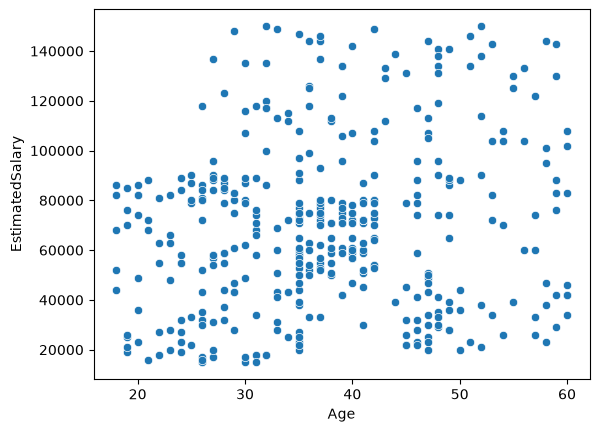

In [25]:
sns.scatterplot(x='Age', y='EstimatedSalary', data=df)

In [26]:
X = df.iloc[:, 0:2]
y = df.iloc[:, -1]

In [28]:
X

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000
...,...,...
395,46,41000
396,51,23000
397,50,20000
398,36,33000


In [29]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [32]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from tensorflow.keras.layers import Dense

In [39]:
model = Sequential()
model.add(Dense(128, activation='relu', input_dim=2))
model.add(Dense(1, activation='sigmoid'))  # Change 128 to 1 here

C:\Users\Admin\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [40]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                      │ (None, 128)                 │             384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
model.compile(optimizer='Adam' ,loss='binary_crossentropy' ,metrics=['accuracy'])

In [42]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=100)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.4844 - loss: 257.0383 - val_accuracy: 0.6000 - val_loss: 50.9391
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5625 - loss: 49.8086 - val_accuracy: 0.4000 - val_loss: 101.5477
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4719 - loss: 88.0781 - val_accuracy: 0.6000 - val_loss: 47.7284
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5469 - loss: 57.8215 - val_accuracy: 0.4000 - val_loss: 63.4544
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4844 - loss: 28.6932 - val_accuracy: 0.4000 - val_loss: 48.1825
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5844 - loss: 44.8597 - val_accuracy: 0.6000 - val_loss: 90.1905
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5031 - loss: 117.0123 - val_accuracy: 0.6000 - val_loss: 197.7271
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.4969 - loss: 152.461

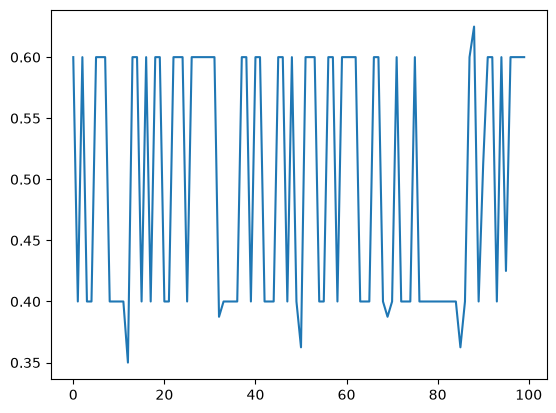

In [43]:
import matplotlib.pyplot as plt

plt.plot(history.history['val_accuracy'])

In [44]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [51]:
model = Sequential()

model.add(Dense(128, activation='relu', input_dim=2))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=100)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 123ms/step - accuracy: 0.6969 - loss: 0.6791 - val_accuracy: 0.7625 - val_loss: 0.6430
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.8219 - loss: 0.6279 - val_accuracy: 0.8000 - val_loss: 0.5919
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8281 - loss: 0.5858 - val_accuracy: 0.8250 - val_loss: 0.5489
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8406 - loss: 0.5497 - val_accuracy: 0.8125 - val_loss: 0.5140
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8406 - loss: 0.5184 - val_accuracy: 0.8000 - val_loss: 0.4835
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8531 - loss: 0.4902 - val_accuracy: 0.7875 - val_loss: 0.4558
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.8438 - loss: 0.4653 - val_accuracy: 0.7875 - val_loss: 0.4320
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8562 - loss: 0.4411 - val_accuracy: 0

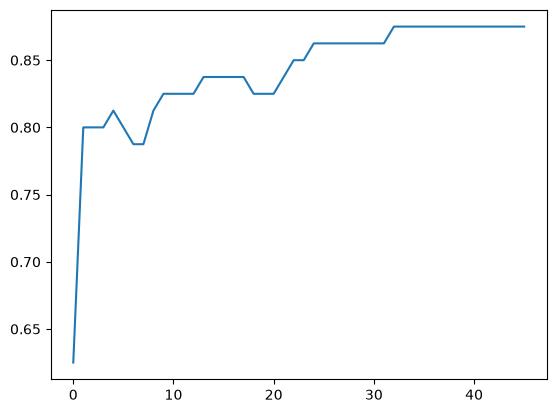

In [56]:
import matplotlib.pyplot as plt

plt.plot(history.history['val_accuracy'])

In [54]:
from tensorflow.keras.callbacks import EarlyStopping

# 1. Define your early stopping callback
callback = EarlyStopping(
    monitor='val_loss',
    min_delta=0.001,
    patience=3,
    verbose=1,
    mode='auto',
    restore_best_weights=False
)

model = Sequential()
model.add(Dense(128, activation='relu', input_dim=2))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 2. Add 'callbacks=[callback]' here inside model.fit()
history1 = model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=500, callbacks=[callback])

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.5969 - loss: 0.6854 - val_accuracy: 0.7125 - val_loss: 0.6537
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7656 - loss: 0.6252 - val_accuracy: 0.7625 - val_loss: 0.5959
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.7937 - loss: 0.5771 - val_accuracy: 0.7750 - val_loss: 0.5464
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8156 - loss: 0.5348 - val_accuracy: 0.7750 - val_loss: 0.5060
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8156 - loss: 0.4993 - val_accuracy: 0.7875 - val_loss: 0.4715
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.8188 - loss: 0.4695 - val_accuracy: 0.7875 - val_loss: 0.4421
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8375 - loss: 0.4420 - val_accuracy: 0.7875 - val_loss: 0.4166
Epoch 8/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8500 - loss: 0.4185 - val_accuracy: 0.

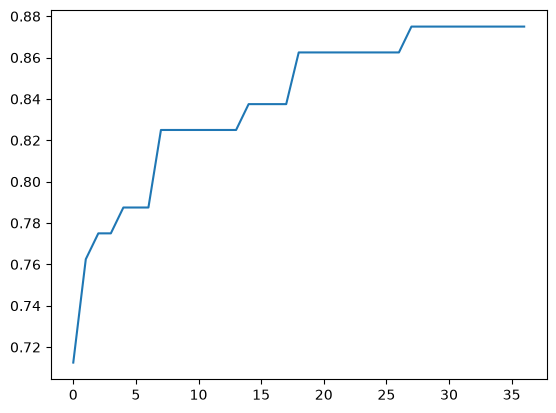

In [55]:
import matplotlib.pyplot as plt

plt.plot(history1.history['val_accuracy'])